In [1]:
from dataloader import get_participants_data, get_participants_demographics, load_all_data
import pandas as pd
import numpy as np

import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
plt.rcParams['text.usetex'] = True
plt.rcParams['text.latex.preamble'] = r'''\usepackage{libertine}\usepackage{fontawesome5}\usepackage{xcolor}'''
plt.rcParams['ps.usedistiller'] = 'xpdf'
import seaborn as sns
sns.set_theme(style='ticks')

In [2]:
colors = sns.color_palette('Blues', as_cmap=False, n_colors=3)
interfaces = [
    'pointwise',        # UI1
    'pairwise',         # UI2
    'listwise-rating',  # UI3
    'listwise-notie',   # UI4
    'listwise-cantie',  # UI5
    'listwise-ranking', # UI6
]
df_begins, df_all, df_finishs, df_demographic = load_all_data()

pointwise
pairwise
listwise-rating
listwise-notie
listwise-cantie
listwise-ranking
pointwise
pairwise
listwise-rating
listwise-notie
listwise-cantie
listwise-ranking


In [20]:
print(df_begins.shape)
print(df_all.shape)
print(df_finishs.shape)
print(df_demographic.shape)

(360, 16)
(8935, 21)
(1080, 20)
(360, 20)


count unique               top freq
domain interface                                           
image  listwise-cantie     30      1   listwise-cantie   30
       listwise-notie      30      1    listwise-notie   30
       listwise-ranking    30      1  listwise-ranking   30
       listwise-rating     30      1   listwise-rating   30
       pairwise            30      1          pairwise   30
       pointwise           30      1         pointwise   30
text   listwise-cantie     30      1   listwise-cantie   30
       listwise-notie      30      1    listwise-notie   30
       listwise-ranking    30      1  listwise-ranking   30
       listwise-rating     30      1   listwise-rating   30
       pairwise            30      1          pairwise   30
       pointwise           30      1         pointwise   30

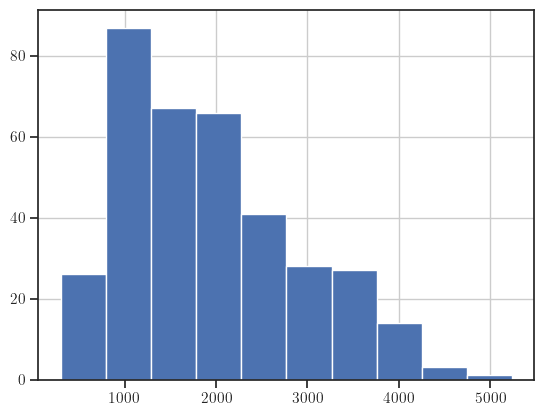

In [3]:
df_demographic.to_csv('processed/demographics.csv', index=False)
df_demographic.time_taken.hist()
df_demographic.groupby(['domain', 'interface']).interface.describe()

## Gender

In [4]:
df_demographic['gender'] = df_demographic.gender.map({0: 'female', 1: 'male', 2: 'diverse'})
df_demographic.groupby(['gender']).count()

,domain,user_id,session_id,time_taken,total_approvals,age_x,age_y,sex,fluent_languages,ethnicity_simplified,birth,residence,language,student,employment,interface,expertise,workExperience,lastExperience
gender,,,,,,,,,,,,,,,,,,,
diverse,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4
female,170,170,170,170,170,170,170,170,170,170,170,170,170,170,170,170,170,170,170
male,186,186,186,186,186,186,186,186,186,186,186,186,186,186,186,186,186,186,186


## Age

In [5]:
df_demographic.age_x.min(), df_demographic.age_x.max()

('18', '66')

In [6]:
np.array(df_demographic.age_x, dtype=np.float32).mean()

28.13611

In [7]:
np.array(df_demographic.age_x, dtype=np.float32).std()

8.382245

## Language Expertise

In [8]:
df_lang = df_demographic[df_demographic.domain == 'text']
df_lang.expertise = df_lang.expertise.map({
    0: 'A1',
    1: 'A2',
    2: 'B1',
    3: 'B2',
    4: 'C1',
    5: 'C2',
})
df_lang = df_lang.groupby(['expertise']).count().reset_index()[['expertise', 'domain']].rename(columns={'domain': 'count'})
df_lang['frequency'] = df_lang['count'] * 100 / df_lang['count'].sum()
df_lang

,expertise,count,frequency
0,A1,1,0.555556
1,A2,1,0.555556
2,B1,7,3.888889
3,B2,39,21.666667
4,C1,78,43.333333
5,C2,54,30.000000


In [9]:
df_lang = df_demographic[df_demographic.domain == 'image']
df_lang.expertise = df_lang.expertise.map({
    0: 'None',
    1: 'Novice',
    2: 'Intermediate',
    3: 'Experienced',
    4: 'Expert',
})
df_lang = df_lang.groupby(['expertise']).count().reset_index()[['expertise', 'domain']].rename(columns={'domain': 'count'})
df_lang['frequency'] = df_lang['count'] * 100 / df_lang['count'].sum()
df_lang

,expertise,count,frequency
0,Experienced,19,10.555556
1,Expert,1,0.555556
2,Intermediate,54,30.000000
3,None,22,12.222222
4,Novice,84,46.666667


## Photo Editing Expertise

## Check inconsistent demographics between questionnaire and platform data

In [10]:
df_demographic[df_demographic.user_id == 'XP0073']

,domain,user_id,session_id,time_taken,total_approvals,age_x,age_y,sex,gender,fluent_languages,ethnicity_simplified,birth,residence,language,student,employment,interface,expertise,workExperience,lastExperience


In [18]:
import math

for idx, row in df_demographic.iterrows():
    if abs(int(row.age_x) - int(row.age_y)) > 1 or (row.gender == 0 and row.sex != 'Female') or (row.gender == 1 and row.sex != 'Male'):
        print(row.user_id, row.interface, row.age_x, row.age_y, row.gender, row.sex)

P233 pairwise 26 28 male Male
P015 listwise-ranking 39 47 male Male
P249 listwise-ranking 41 50 female Female
P211 pointwise 34 27 male Male
P144 pairwise 22 27 female Female
P190 listwise-notie 35 38 male Male
P096 listwise-cantie 40 43 female Male
P272 listwise-ranking 20 22 male Male


## Check if response time is too fast

In [12]:
df = df_all[['userID', 'interface', 'timePresent', 'timeSubmit']]
df['decision_time'] = (pd.to_datetime(df.timeSubmit, origin='unix', unit='ms') - pd.to_datetime(df.timePresent, origin='unix', unit='ms')) / np.timedelta64(1, 's')

fast_participants = {}
for idx, row in df.iterrows():
    if row.decision_time < 1:
        print(row.userID, row.interface, row.decision_time)
        fast_participants[row.userID] = row.interface

print('OK' if len(fast_participants) == 0 else 'NOT OK')

OK


In [ ]:
# load all csv from prolific folder
import glob
import pandas as pd

df_text = pd.DataFrame()
for file in glob.glob('text/**/**/*.csv'):
    df_text = pd.concat([df_text, pd.read_csv(file)], ignore_index=True)
    df_text['domain'] = 'text'

df_image = pd.DataFrame()
for file in glob.glob('image/**/**/*.csv'):
    df_image = pd.concat([df_image, pd.read_csv(file)], ignore_index=True)
    df_image['domain'] = 'image'

df = pd.concat([df_text, df_image], ignore_index=True)
df

In [ ]:
df[df.domain == 'text'].groupby('Country of residence').describe()

In [ ]:
df[df.domain == 'image'].groupby('Country of residence').describe()

In [ ]:
df[df.domain == 'text'].groupby('Language').Language.describe()

In [ ]:
df.groupby('Nationality').Nationality.describe()
